# ASVspoof 2019 LA – dataset check

This notebook checks whether the ASVspoof 2019 LA files on disk match what is written in the official documentation: `README.txt`, `README.LA.txt`, the evaluation plan and the main paper (Wang et al., 2020).

**How to use it**

- Run the cells from top to bottom.
- The notebook only **reads** the data – nothing in `datasets/` is changed.
- Every check prints one line:
  - `[OK]` – the files match the documentation,
  - `[DIFF]` – the files do not match the documentation,
  - `[INFO]` – an observation, there is nothing to compare with.

**Output files**

In `outputs/01_asvspoof_2019_la_dataset_exploration_output/` (not committed to git):

- `audio_info.csv` – properties of every audio file (step 8a),
- `checks.csv` – table of all checks (step 9).

In `results/01_asvspoof_2019/01_asvspoof_2019_la_dataset_exploration_output/` (committed to git):

- `dataset_exploration_report.md` – report with the results of all steps (step 10).

### Setup – paths and settings

**What it does:** Loads the libraries, finds the project folder and sets the paths to the dataset (`datasets/01_asvspoof_2019/LA`), to the outputs folder for working files (`outputs/01_asvspoof_2019_la_dataset_exploration_output`) and to the results folder for the report (`results/01_asvspoof_2019/01_asvspoof_2019_la_dataset_exploration_output`). It also defines the names of the three parts of the dataset (train, dev, eval) and of their label files.

**Why:** All the next cells use these paths and names. The paths are relative to the project folder, so the notebook works on any computer without changes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import soundfile as sf
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("pyproject.toml not found")


REPO_ROOT = find_repo_root(Path.cwd())
LA_DIR = REPO_ROOT / "datasets" / "01_asvspoof_2019" / "LA"
CM_DIR = LA_DIR / "ASVspoof2019_LA_cm_protocols"
ASV_DIR = LA_DIR / "ASVspoof2019_LA_asv_protocols"
NOTEBOOK_NAME = "01_asvspoof_2019_la_dataset_exploration"
OUTPUTS_DIR = REPO_ROOT / "outputs" / f"{NOTEBOOK_NAME}_output"
RESULTS_DIR = REPO_ROOT / "results" / "01_asvspoof_2019" / f"{NOTEBOOK_NAME}_output"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "dev", "eval"]
SPLIT_PREFIX = {"train": "LA_T_", "dev": "LA_D_", "eval": "LA_E_"}
PROTOCOL_FILES = {
    "train": "ASVspoof2019.LA.cm.train.trn.txt",
    "dev": "ASVspoof2019.LA.cm.dev.trl.txt",
    "eval": "ASVspoof2019.LA.cm.eval.trl.txt",
}

print("LA folder:", LA_DIR.relative_to(REPO_ROOT), "| exists:", LA_DIR.exists())

LA folder: datasets/01_asvspoof_2019/LA | exists: True


### Check list – helper function

**What it does:** Defines `add_check`, a small function that compares an **expected** value (from the documentation) with a **measured** value (from the files on disk). It prints `[OK]` if they match, `[DIFF]` if they do not, and `[INFO]` if there is nothing to compare with (only an observation). Every result is saved in the list `checks`.

**Why:** All results are collected in one place, so at the end they can be shown in one table and written to the report.

In [2]:
checks = []


def add_check(check: str, source: str, expected, measured) -> None:
    ok = None if expected is None else expected == measured
    checks.append(
        {
            "check": check,
            "source": source,
            "expected": expected,
            "measured": measured,
            "ok": ok,
        }
    )
    status = "INFO" if ok is None else ("OK" if ok else "DIFF")
    print(f"[{status}] {check}: expected={expected!r}, measured={measured!r}")

### Step 1 – Structure of the LA folder

**What it does:** Lists the folders and files inside `LA/` and compares them with the list in `README.txt` (6 folders and `README.LA.txt`).

**Why:** Confirms that the dataset was downloaded and unpacked completely.

In [3]:
expected_items = {
    "ASVspoof2019_LA_asv_protocols",
    "ASVspoof2019_LA_asv_scores",
    "ASVspoof2019_LA_cm_protocols",
    "ASVspoof2019_LA_train",
    "ASVspoof2019_LA_dev",
    "ASVspoof2019_LA_eval",
    "README.LA.txt",
}
found_items = {p.name for p in LA_DIR.iterdir() if not p.name.startswith(".")}

add_check(
    "LA folder contents",
    "README.txt, directory structure",
    expected_items,
    found_items,
)

[OK] LA folder contents: expected={'ASVspoof2019_LA_dev', 'ASVspoof2019_LA_cm_protocols', 'ASVspoof2019_LA_asv_scores', 'ASVspoof2019_LA_eval', 'ASVspoof2019_LA_train', 'README.LA.txt', 'ASVspoof2019_LA_asv_protocols'}, measured={'ASVspoof2019_LA_dev', 'ASVspoof2019_LA_cm_protocols', 'ASVspoof2019_LA_train', 'ASVspoof2019_LA_eval', 'README.LA.txt', 'ASVspoof2019_LA_asv_protocols', 'ASVspoof2019_LA_asv_scores'}


### Step 2 – Load the label files

**What it does:** Reads the three label (protocol) files – train, dev and eval – into one table. Each row is one recording: speaker, file name, attack, real (`bonafide`) or fake (`spoof`), and the part of the dataset (`split`).

**Why:** All the next checks use this table.

In [4]:
COLUMNS = ["speaker_id", "file_name", "unused", "system_id", "key"]

frames = []
for split, file_name in PROTOCOL_FILES.items():
    df = pd.read_csv(
        CM_DIR / file_name,
        sep=" ",
        header=None,
        names=COLUMNS,
        dtype=str,
        keep_default_na=False,
    )
    df["split"] = split
    frames.append(df)

cm = pd.concat(frames, ignore_index=True)
print("Rows:", len(cm))
display(cm)

Rows: 121461


,speaker_id,file_name,unused,system_id,key,split
0,LA_0079,LA_T_1138215,-,-,bonafide,train
1,LA_0079,LA_T_1271820,-,-,bonafide,train
2,LA_0079,LA_T_1272637,-,-,bonafide,train
3,LA_0079,LA_T_1276960,-,-,bonafide,train
4,LA_0079,LA_T_1341447,-,-,bonafide,train
...,...,...,...,...,...,...
121456,LA_0004,LA_E_1665632,-,-,bonafide,eval
121457,LA_0038,LA_E_5085671,-,A09,spoof,eval
121458,LA_0012,LA_E_4926022,-,A16,spoof,eval
121459,LA_0052,LA_E_2894498,-,-,bonafide,eval


### Step 3 – Format of the label files

**What it does:** Checks that every line has 5 columns, the unused column always contains `-`, labels are only `bonafide` or `spoof`, real recordings have no attack ID, fake recordings have an attack ID from A01 to A19, and no file name appears twice.

**Why:** If the label files were broken, every later result would be wrong.

In [5]:
columns_per_line = set()
for file_name in PROTOCOL_FILES.values():
    with open(CM_DIR / file_name, encoding="utf-8") as f:
        columns_per_line |= {len(line.split()) for line in f if line.strip()}

add_check("Columns per line", "README.LA.txt, section 3", {5}, columns_per_line)
add_check("Values of the unused column", "README.LA.txt, section 3", {"-"}, set(cm["unused"]))
add_check("Values of key", "README.LA.txt, section 3", {"bonafide", "spoof"}, set(cm["key"]))
add_check(
    "system_id for bona fide",
    "README.LA.txt, section 3",
    {"-"},
    set(cm.loc[cm["key"] == "bonafide", "system_id"]),
)
add_check(
    "system_id for spoof",
    "README.LA.txt, section 3",
    {f"A{i:02d}" for i in range(1, 20)},
    set(cm.loc[cm["key"] == "spoof", "system_id"]),
)
add_check("Duplicated file names", "-", 0, int(cm["file_name"].duplicated().sum()))

[OK] Columns per line: expected={5}, measured={5}
[OK] Values of the unused column: expected={'-'}, measured={'-'}
[OK] Values of key: expected={'bonafide', 'spoof'}, measured={'bonafide', 'spoof'}
[OK] system_id for bona fide: expected={'-'}, measured={'-'}
[OK] system_id for spoof: expected={'A15', 'A16', 'A06', 'A11', 'A07', 'A18', 'A03', 'A14', 'A13', 'A08', 'A10', 'A12', 'A01', 'A02', 'A19', 'A05', 'A09', 'A04', 'A17'}, measured={'A15', 'A16', 'A06', 'A11', 'A07', 'A18', 'A03', 'A14', 'A13', 'A08', 'A10', 'A12', 'A01', 'A02', 'A19', 'A05', 'A09', 'A04', 'A17'}
[OK] Duplicated file names: expected=0, measured=0


### Step 4 – Number of recordings per split

**What it does:** Counts real and fake recordings in train, dev and eval and compares the numbers with the main paper (p. 5, section 2.3).

**Why:** Confirms that the dataset on disk is complete and the same as the one described in the paper.

In [6]:
counts = pd.crosstab(cm["split"], cm["key"]).reindex(SPLITS)
counts["total"] = counts.sum(axis=1)
display(counts)

expected_counts = {
    "train": (2580, 22800),
    "dev": (2548, 22296),
    "eval": (7355, 63882),
}
for split, expected in expected_counts.items():
    measured = (int(counts.loc[split, "bonafide"]), int(counts.loc[split, "spoof"]))
    add_check(
        f"{split}: bona fide / spoof",
        "main paper, p. 5, section 2.3",
        expected,
        measured,
    )

key,bonafide,spoof,total
split,,,
train,2580,22800,25380
dev,2548,22296,24844
eval,7355,63882,71237


[OK] train: bona fide / spoof: expected=(2580, 22800), measured=(2580, 22800)
[OK] dev: bona fide / spoof: expected=(2548, 22296), measured=(2548, 22296)
[OK] eval: bona fide / spoof: expected=(7355, 63882), measured=(7355, 63882)


### Step 5 – Attacks per split

**What it does:** Shows which fake-generating systems (attacks A01–A19) appear in each part and how many recordings each has. Expected: only A01–A06 in train and dev, only A07–A19 in eval.

**Why:** Confirms that the final test (eval) contains new kinds of fakes that the detectors never saw during training.

In [7]:
spoof = cm[cm["key"] == "spoof"]
attacks = pd.crosstab(spoof["system_id"], spoof["split"]).reindex(columns=SPLITS, fill_value=0)
display(attacks)

known = {f"A{i:02d}" for i in range(1, 7)}
eval_attacks = {f"A{i:02d}" for i in range(7, 20)}
expected_attacks = {"train": known, "dev": known, "eval": eval_attacks}

for split, expected in expected_attacks.items():
    add_check(
        f"{split}: attack IDs",
        "main paper, p. 6, Table 1",
        expected,
        set(spoof.loc[spoof["split"] == split, "system_id"]),
    )

split,train,dev,eval
system_id,,,
A01,3800,3716,0
A02,3800,3716,0
A03,3800,3716,0
A04,3800,3716,0
A05,3800,3716,0
A06,3800,3716,0
A07,0,0,4914
A08,0,0,4914
A09,0,0,4914


[OK] train: attack IDs: expected={'A03', 'A01', 'A02', 'A05', 'A04', 'A06'}, measured={'A03', 'A01', 'A02', 'A05', 'A04', 'A06'}
[OK] dev: attack IDs: expected={'A03', 'A01', 'A02', 'A05', 'A04', 'A06'}, measured={'A03', 'A01', 'A02', 'A05', 'A04', 'A06'}
[OK] eval: attack IDs: expected={'A13', 'A08', 'A10', 'A11', 'A15', 'A12', 'A19', 'A09', 'A07', 'A16', 'A18', 'A17', 'A14'}, measured={'A13', 'A08', 'A10', 'A11', 'A15', 'A12', 'A19', 'A09', 'A07', 'A16', 'A18', 'A17', 'A14'}


### Step 6 – Speakers

**What it does:** Counts the different speakers in each part and checks that no person appears in two parts.

**Why:** If the same person were in train and eval, the final test would be easier than it should be.

In [8]:
speakers = {split: set(cm.loc[cm["split"] == split, "speaker_id"]) for split in SPLITS}
speaker_summary = pd.DataFrame(
    {"split": SPLITS, "speakers": [len(speakers[split]) for split in SPLITS]}
).set_index("split")
display(speaker_summary)

# main paper counts all speakers (target + non-target), README.txt only target speakers
add_check("train: speakers", "main paper, p. 3, section 2.1", 20, len(speakers["train"]))
add_check("dev: speakers (all)", "main paper, p. 3, section 2.1", 20, len(speakers["dev"]))
add_check("eval: speakers (all)", "main paper, p. 3, section 2.1", 67, len(speakers["eval"]))

for a, b in [("train", "dev"), ("train", "eval"), ("dev", "eval")]:
    add_check(
        f"Speakers shared by {a} and {b}",
        "README.txt; main paper, p. 3, section 2.1",
        set(),
        speakers[a] & speakers[b],
    )

,speakers
split,
train,20
dev,20
eval,67


[OK] train: speakers: expected=20, measured=20
[OK] dev: speakers (all): expected=20, measured=20
[OK] eval: speakers (all): expected=67, measured=67
[OK] Speakers shared by train and dev: expected=set(), measured=set()
[OK] Speakers shared by train and eval: expected=set(), measured=set()
[OK] Speakers shared by dev and eval: expected=set(), measured=set()


### Step 6b – Gender of the target speakers

**What it does:** Reads the enrollment lists (recordings used to register a person's voice in the speaker verification system) and counts women and men among the target speakers in dev and eval.

**Why:** Compares the numbers with `README.txt` and the main paper. The enrollment recordings are also needed in step 7, because they are audio files without labels.

In [9]:
enroll_rows = []
for split in ["dev", "eval"]:
    for gender in ["female", "male"]:
        path = ASV_DIR / f"ASVspoof2019.LA.asv.{split}.{gender}.trn.txt"
        with open(path, encoding="utf-8") as f:
            for line in f:
                if not line.strip():
                    continue
                speaker_id, file_list = line.split()
                for file_name in file_list.split(","):
                    enroll_rows.append(
                        {
                            "split": split,
                            "gender": gender,
                            "speaker_id": speaker_id,
                            "file_name": file_name,
                        }
                    )

enroll = pd.DataFrame(enroll_rows)
target_speakers = enroll.drop_duplicates(["split", "speaker_id"])
target_gender = target_speakers.groupby(["split", "gender"]).size()
display(target_gender)

for split, expected in {"dev": (6, 4), "eval": (27, 21)}.items():
    measured = (int(target_gender[(split, "female")]), int(target_gender[(split, "male")]))
    add_check(
        f"{split}: target speakers (F, M)",
        "README.txt; main paper, p. 4, Figure 2",
        expected,
        measured,
    )

split  gender
dev    female     6
       male       4
eval   female    27
       male      21
dtype: int64

[OK] dev: target speakers (F, M): expected=(6, 4), measured=(6, 4)
[OK] eval: target speakers (F, M): expected=(27, 21), measured=(27, 21)


### Step 7 – Audio files vs labels

**What it does:** For each part, compares the audio files in the `flac/` folder with the list of recordings in the label file: files missing on disk, extra files without labels and files with a wrong name prefix. The extra files should be exactly the enrollment recordings from step 6b.

**Why:** Every labelled recording must exist as a file, and we need to know which files have no label, so they can be skipped in the experiments.

In [10]:
file_summary_rows = []
for split in SPLITS:
    audio_dir = LA_DIR / f"ASVspoof2019_LA_{split}" / "flac"
    on_disk = {p.stem for p in audio_dir.glob("*.flac")}
    in_protocol = set(cm.loc[cm["split"] == split, "file_name"])
    in_enroll = set(enroll.loc[enroll["split"] == split, "file_name"])
    missing = in_protocol - on_disk
    extra = on_disk - in_protocol
    wrong_prefix = [n for n in on_disk if not n.startswith(SPLIT_PREFIX[split])]

    print(f"\n{split}: audio files on disk = {len(on_disk)}, rows in protocol = {len(in_protocol)}")
    add_check(f"{split}: protocol files missing on disk", "-", 0, len(missing))
    add_check(
        f"{split}: extra audio files (not in CM protocol)",
        "README.txt, point 3 (ASV enrollment data)",
        len(in_enroll),
        len(extra),
    )
    add_check(
        f"{split}: extra files are exactly the ASV enrollment files",
        "README.txt, point 3; ASV *.trn.txt files",
        True,
        extra == in_enroll,
    )
    add_check(
        f"{split}: files with wrong name prefix",
        "README.LA.txt, section 2",
        0,
        len(wrong_prefix),
    )
    file_summary_rows.append(
        {
            "split": split,
            "files_on_disk": len(on_disk),
            "rows_in_protocol": len(in_protocol),
            "missing_on_disk": len(missing),
            "extra_files": len(extra),
            "asv_enrollment_files": len(in_enroll),
            "wrong_prefix": len(wrong_prefix),
        }
    )

file_summary = pd.DataFrame(file_summary_rows).set_index("split")
display(file_summary)


train: audio files on disk = 25380, rows in protocol = 25380
[OK] train: protocol files missing on disk: expected=0, measured=0
[OK] train: extra audio files (not in CM protocol): expected=0, measured=0
[OK] train: extra files are exactly the ASV enrollment files: expected=True, measured=True
[OK] train: files with wrong name prefix: expected=0, measured=0

dev: audio files on disk = 24986, rows in protocol = 24844
[OK] dev: protocol files missing on disk: expected=0, measured=0
[OK] dev: extra audio files (not in CM protocol): expected=142, measured=142
[OK] dev: extra files are exactly the ASV enrollment files: expected=True, measured=True
[OK] dev: files with wrong name prefix: expected=0, measured=0

eval: audio files on disk = 71933, rows in protocol = 71237
[OK] eval: protocol files missing on disk: expected=0, measured=0
[OK] eval: extra audio files (not in CM protocol): expected=696, measured=696
[OK] eval: extra files are exactly the ASV enrollment files: expected=True, measu

,files_on_disk,rows_in_protocol,missing_on_disk,extra_files,asv_enrollment_files,wrong_prefix
split,,,,,,
train,25380,25380,0,0,0,0
dev,24986,24844,0,142,142,0
eval,71933,71237,0,696,696,0


### Step 8a – Read the audio file properties

**What it does:** Reads only the header of every audio file (not the sound itself): format, sample rate, bit depth, number of channels and length. The result is saved to `outputs/01_asvspoof_2019_la_dataset_exploration_output/audio_info.csv`; the next time the notebook loads this file instead of reading all recordings again. **The first run takes a few minutes.**

**Why:** These properties are needed for the technical checks in the next cell and later for the table of recording features (silence, loudness, bandwidth, duration).

In [11]:
INFO_CACHE = OUTPUTS_DIR / "audio_info.csv"

if INFO_CACHE.exists():
    info = pd.read_csv(INFO_CACHE, dtype={"file_name": str})
    print("Loaded from cache:", INFO_CACHE.relative_to(REPO_ROOT))
else:
    rows = []
    for split in SPLITS:
        paths = sorted((LA_DIR / f"ASVspoof2019_LA_{split}" / "flac").glob("*.flac"))
        print(f"Reading {len(paths)} files from {split} ...")
        for path in paths:
            meta = sf.info(path)
            rows.append(
                {
                    "split": split,
                    "file_name": path.stem,
                    "format": meta.format,
                    "subtype": meta.subtype,
                    "samplerate": meta.samplerate,
                    "channels": meta.channels,
                    "frames": meta.frames,
                }
            )
    info = pd.DataFrame(rows)
    info["duration_s"] = info["frames"] / info["samplerate"]
    info.to_csv(INFO_CACHE, index=False)
    print("Saved to:", INFO_CACHE.relative_to(REPO_ROOT))

# keep only files from the CM protocols (without ASV enrollment files)
audio = info.merge(cm[["file_name", "key", "system_id", "speaker_id"]], on="file_name", how="inner")
print("Audio files with labels:", len(audio))

Loaded from cache: outputs/01_asvspoof_2019_la_dataset_exploration_output/audio_info.csv
Audio files with labels: 121461


### Step 8b – Check the audio file properties

**What it does:** Checks that all files are FLAC, 16 kHz and 16-bit, shows the number of channels, and computes duration statistics for each part, separately for real and fake recordings. The median duration is compared with "one to two seconds" from the evaluation plan.

**Why:** Confirms the technical description of the dataset. A clear difference in duration between real and fake recordings could be a shortcut that detectors use.

In [12]:
add_check("File format", "README.LA.txt, section 2", {"FLAC"}, set(audio["format"]))
add_check(
    "Sample rate [Hz]",
    "main paper, p. 3, section 2.1; README.LA.txt, section 2",
    {16000},
    set(audio["samplerate"]),
)
add_check(
    "Bit depth (subtype)",
    "main paper, p. 3, section 2.1; README.LA.txt, section 2",
    {"PCM_16"},
    set(audio["subtype"]),
)
add_check("Number of channels", "not stated (observation)", None, set(audio["channels"]))

property_values = pd.DataFrame(
    {
        "property": ["format", "subtype", "samplerate", "channels"],
        "values found": [
            ", ".join(map(str, sorted(audio[col].unique())))
            for col in ["format", "subtype", "samplerate", "channels"]
        ],
    }
).set_index("property")
display(property_values)

duration_stats = audio.groupby(["split", "key"])["duration_s"].describe()
duration_stats["count"] = duration_stats["count"].astype(int)
display(duration_stats.round(2))

median_duration = round(float(audio["duration_s"].median()), 2)
add_check("Median duration [s]", "evaluation plan, p. 3, Table 1 caption", None, median_duration)
add_check(
    "Median duration within 1-2 s",
    "evaluation plan, p. 3, Table 1 caption",
    True,
    1.0 <= median_duration <= 2.0,
)

[OK] File format: expected={'FLAC'}, measured={'FLAC'}
[OK] Sample rate [Hz]: expected={16000}, measured={16000}
[OK] Bit depth (subtype): expected={'PCM_16'}, measured={'PCM_16'}
[INFO] Number of channels: expected=None, measured={1}


,values found
property,
format,FLAC
subtype,PCM_16
samplerate,16000
channels,1


count  mean   std   min   25%   50%   75%    max
split key                                                       
dev   bonafide   2548  3.51  1.09  1.28  2.73  3.39  4.14  11.39
      spoof     22296  3.47  1.49  0.70  2.41  3.27  4.25  11.59
eval  bonafide   7355  3.40  1.06  0.90  2.64  3.20  3.92  13.01
      spoof     63882  3.07  1.52  0.47  1.98  2.75  3.81  13.03
train bonafide   2580  3.39  0.99  1.36  2.69  3.24  3.92  11.13
      spoof     22800  3.43  1.46  0.65  2.39  3.20  4.14  13.19

[INFO] Median duration [s]: expected=None, measured=2.98
[DIFF] Median duration within 1-2 s: expected=True, measured=False


### Step 8c – Duration histogram

**What it does:** Draws one chart showing how many recordings have each duration, with real and fake recordings on top of each other.

**Why:** Makes it easy to see at a glance whether real and fake recordings differ in length.

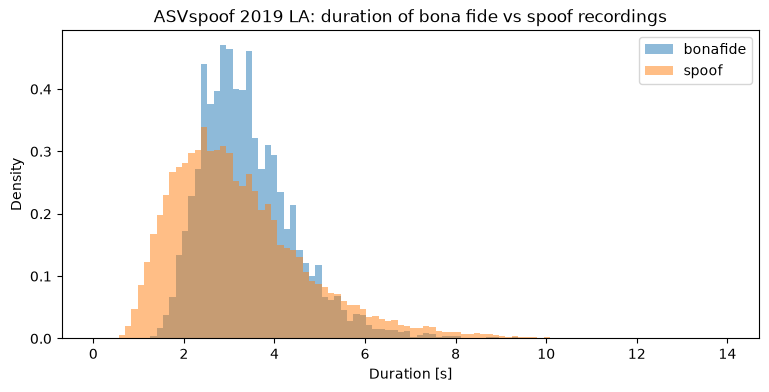

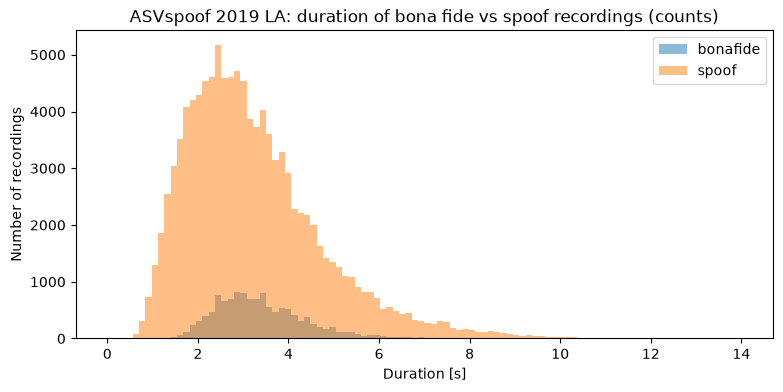

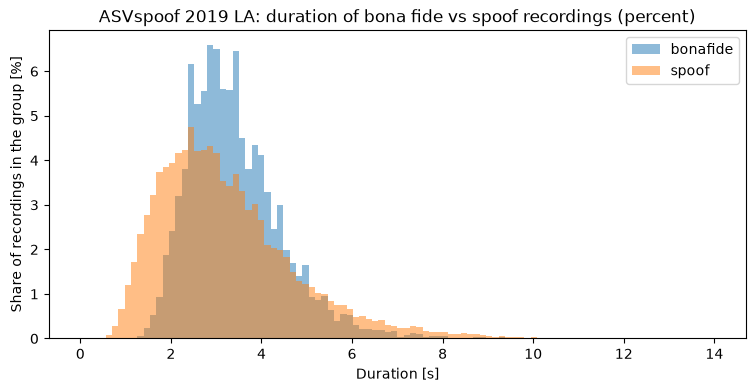

In [13]:
import numpy as np

max_duration = float(np.ceil(audio["duration_s"].max()))
bins = np.linspace(0, max_duration, 101)

fig, ax = plt.subplots(figsize=(9, 4))
for key, group in audio.groupby("key"):
    ax.hist(group["duration_s"], bins=bins, alpha=0.5, density=True, label=key)
ax.set_xlabel("Duration [s]")
ax.set_ylabel("Density")
ax.set_title("ASVspoof 2019 LA: duration of bona fide vs spoof recordings")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for key, group in audio.groupby("key"):
    ax.hist(group["duration_s"], bins=bins, alpha=0.5, density=False, label=key)
ax.set_xlabel("Duration [s]")
ax.set_ylabel("Number of recordings")
ax.set_title("ASVspoof 2019 LA: duration of bona fide vs spoof recordings (counts)")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for key, group in audio.groupby("key"):
    weights = [100 / len(group)] * len(group)
    ax.hist(group["duration_s"], bins=bins, alpha=0.5, weights=weights, label=key)
ax.set_xlabel("Duration [s]")
ax.set_ylabel("Share of recordings in the group [%]")
ax.set_title("ASVspoof 2019 LA: duration of bona fide vs spoof recordings (percent)")
ax.legend()
plt.show()

### Step 9 – Summary of all checks

**What it does:** Shows all checks in one table with their status (OK, DIFF, INFO), lists only the differences and saves the table to `outputs/01_asvspoof_2019_la_dataset_exploration_output/checks.csv`.

**Why:** One place to see what matches the documentation and what does not.

In [14]:
summary = pd.DataFrame(checks)
summary["status"] = summary["ok"].map({True: "OK", False: "DIFF"}).fillna("INFO")
summary = summary[["status", "check", "expected", "measured", "source"]]
display(summary)

print("\nDifferences:")
display(summary[summary["status"] == "DIFF"])

summary.to_csv(OUTPUTS_DIR / "checks.csv", index=False)
print("Saved to:", OUTPUTS_DIR.relative_to(REPO_ROOT) / "checks.csv")

,status,check,expected,measured,source
0,OK,LA folder contents,"{ASVspoof2019_LA_dev, ASVspoof2019_LA_cm_proto...","{ASVspoof2019_LA_dev, ASVspoof2019_LA_cm_proto...","README.txt, directory structure"
1,OK,Columns per line,{5},{5},"README.LA.txt, section 3"
2,OK,Values of the unused column,{-},{-},"README.LA.txt, section 3"
3,OK,Values of key,"{bonafide, spoof}","{bonafide, spoof}","README.LA.txt, section 3"
4,OK,system_id for bona fide,{-},{-},"README.LA.txt, section 3"
5,OK,system_id for spoof,"{A15, A16, A06, A11, A07, A18, A03, A14, A13, ...","{A15, A16, A06, A11, A07, A18, A03, A14, A13, ...","README.LA.txt, section 3"
6,OK,Duplicated file names,0,0,-
7,OK,train: bona fide / spoof,"(2580, 22800)","(2580, 22800)","main paper, p. 5, section 2.3"
8,OK,dev: bona fide / spoof,"(2548, 22296)","(2548, 22296)","main paper, p. 5, section 2.3"
9,OK,eval: bona fide / spoof,"(7355, 63882)","(7355, 63882)","main paper, p. 5, section 2.3"



Differences:


,status,check,expected,measured,source
38,DIFF,Median duration within 1-2 s,True,False,"evaluation plan, p. 3, Table 1 caption"


Saved to: outputs/01_asvspoof_2019_la_dataset_exploration_output/checks.csv


### Step 10 – Report

**What it does:** Writes the results of all steps (tables only, no charts) to `results/01_asvspoof_2019/01_asvspoof_2019_la_dataset_exploration_output/dataset_exploration_report.md`.

**Why:** The results can be read later without running the notebook again.

In [15]:
from datetime import datetime

REPORT_PATH = RESULTS_DIR / "dataset_exploration_report.md"


def fmt(value, max_items: int = 10) -> str:
    if isinstance(value, set):
        if not value:
            return "{} (empty)"
        items = sorted(map(str, value))
        if len(items) > max_items:
            items = [*items[:max_items], f"... (+{len(value) - max_items} more)"]
        return "{" + ", ".join(items) + "}"
    if isinstance(value, float):
        return f"{value:.2f}"
    return str(value)


def df_to_md(df: pd.DataFrame, index: bool = True) -> str:
    data = df.reset_index() if index else df
    header = "| " + " | ".join(map(str, data.columns)) + " |"
    separator = "|" + "---|" * len(data.columns)
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in data.itertuples(index=False)]
    return "\n".join([header, separator, *rows])


status_counts = summary["status"].value_counts()
differences = summary[summary["status"] == "DIFF"]

lines = [
    "# ASVspoof 2019 LA – dataset check report",
    "",
    f"- Generated: {datetime.now():%Y-%m-%d %H:%M}",
    f"- Dataset folder: `{LA_DIR.relative_to(REPO_ROOT)}`",
    f"- Notebook: `notebooks/{NOTEBOOK_NAME}.ipynb`",
    "",
    "## Overview",
    "",
    f"- Checks in total: {len(summary)}",
    f"- OK (matches the documentation): {status_counts.get('OK', 0)}",
    f"- DIFF (does not match): {status_counts.get('DIFF', 0)}",
    f"- INFO (observation, nothing to compare with): {status_counts.get('INFO', 0)}",
    "",
    "## Differences",
    "",
    df_to_md(differences, index=False) if len(differences) else "No differences found.",
    "",
    "## All checks",
    "",
    df_to_md(summary, index=False),
    "",
    "## Step 4 – Number of recordings per split",
    "",
    df_to_md(counts),
    "",
    "## Step 5 – Number of spoofed recordings per attack",
    "",
    df_to_md(attacks),
    "",
    "## Step 6 – Number of speakers per split",
    "",
    df_to_md(speaker_summary),
    "",
    "## Step 6b – Target speakers by gender",
    "",
    df_to_md(target_gender.unstack(fill_value=0)),
    "",
    "## Step 7 – Audio files vs labels",
    "",
    df_to_md(file_summary),
    "",
    "## Step 8 – Audio file properties",
    "",
    df_to_md(property_values),
    "",
    "## Step 8 – Duration of recordings [s]",
    "",
    df_to_md(duration_stats.round(2)),
    "",
]

REPORT_PATH.write_text("\n".join(lines), encoding="utf-8")
print("Report saved to:", REPORT_PATH.relative_to(REPO_ROOT))

Report saved to: results/01_asvspoof_2019/01_asvspoof_2019_la_dataset_exploration_output/dataset_exploration_report.md
